In [70]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv


In [71]:
load_dotenv()
model = ChatGroq(model="openai/gpt-oss-120b",max_tokens=500)

In [72]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str
    evaluation: str

In [73]:
def create_outline(state: BlogState)-> BlogState:
    title = state['title']
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content
    state['outline'] = outline
    return state

In [74]:
def create_blog(state: BlogState)-> BlogState:
    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the following outline \n {outline}'

    content = model.invoke(prompt).content

    state['content']= content
    return state

In [75]:
def evaluation_blog(state:BlogState)-> BlogState:
    outline = state['outline']
    content = state['content']
    prompt = f' Based on my outline -{outline} and my blog - {content}, rate my Blog out of 10.'

    evaluation = model.invoke(prompt).content
    state['evaluation'] = evaluation
    return state

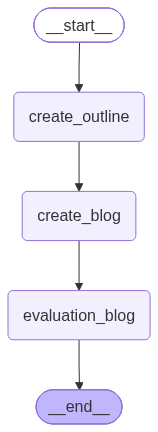

In [76]:
graph = StateGraph(BlogState)

graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)
graph.add_node('evaluation_blog', evaluation_blog)

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', 'evaluation_blog')
graph.add_edge('evaluation_blog', END)
workflow = graph.compile()
workflow


In [77]:
initial_state = {'title': 'Rise of AI in India'}
final_state = workflow.invoke(initial_state)
print(final_state)


{'title': 'Rise of AI in India', 'outline': '**Blog Title:** *The Rise of AI in India: Opportunities, Challenges, and the Road Ahead*  \n\n---\n\n## 1. Introduction  \n- **Hook:** A striking statistic or anecdote (e.g., “India is projected to host 20% of the world’s AI talent by 2030.”)  \n- **Why It Matters:** Briefly explain AI’s global impact and why India’s emergence is a game‑changer.  \n- **Scope of the Post:** What readers will learn – history, ecosystem, key players, use‑cases, challenges, and future outlook.\n\n---\n\n## 2. Historical Context: From Early Adoption to a National Mission  \n### 2.1 Early Foundations (1990s‑2000s)  \n- Government research labs (e.g., C-DAC, ISRO) and early AI projects.  \n- Academic milestones – IITs and IISc pioneering machine‑learning curricula.  \n\n### 2.2 Policy Milestones  \n- **2008:** National Knowledge Network & early e‑governance initiatives.  \n- **2018:** NITI Aayog’s “Strategy for Artificial Intelligence” (first national AI policy).  

In [78]:
print(final_state['outline'])

**Blog Title:** *The Rise of AI in India: Opportunities, Challenges, and the Road Ahead*  

---

## 1. Introduction  
- **Hook:** A striking statistic or anecdote (e.g., “India is projected to host 20% of the world’s AI talent by 2030.”)  
- **Why It Matters:** Briefly explain AI’s global impact and why India’s emergence is a game‑changer.  
- **Scope of the Post:** What readers will learn – history, ecosystem, key players, use‑cases, challenges, and future outlook.

---

## 2. Historical Context: From Early Adoption to a National Mission  
### 2.1 Early Foundations (1990s‑2000s)  
- Government research labs (e.g., C-DAC, ISRO) and early AI projects.  
- Academic milestones – IITs and IISc pioneering machine‑learning curricula.  

### 2.2 Policy Milestones  
- **2008:** National Knowledge Network & early e‑governance initiatives.  
- **2018:** NITI Aayog’s “Strategy for Artificial Intelligence” (first national AI policy).  
- **2020‑2022:** AI for All and Digital India integration.  



In [79]:
print(final_state['content'])

# **The Rise of AI in India: Opportunities, Challenges, and the Road Ahead**

*By [Your Name] – AI & Emerging Tech Analyst*  
*Published Oct 22 2026*  

---  

## 1. Introduction  

### Hook  
> **“India is projected to host 20 % of the world’s AI talent by 2030 – a figure that could dwarf the combined AI workforces of the United Kingdom, Canada, and Israel today.”**  
*(Source: NITI Aayog‑World Economic Forum AI Talent Index, 2025)*  

### Why It Matters  
Artificial Intelligence is no longer a futuristic buzz‑word; it is the engine driving productivity gains, new business models, and societal transformation across the globe. From autonomous‑driving cars in Silicon Valley to AI‑enabled disease‑surveillance in Africa, the technology is reshaping economies at a scale never seen before.  

India’s massive, youthful population, deep‑rooted engineering culture, and accelerating digital infrastructure give it a **unique competitive edge**. If harnessed responsibly, AI can:

- **Accelerate i

In [80]:
print(final_state['evaluation'])

**Rating: 7 / 10**

---

## What’s Working Well

| Element | Strength |
|---------|----------|
| **Hook** | The opening statistic (“20 % of the world’s AI talent by 2030”) is eye‑catching, current, and immediately establishes relevance. |
| **Why It Matters** | You succinctly connect AI’s global impact to India’s specific advantages (population, engineering culture, digital infrastructure). |
| **Scope Outline** | The bullet‑point preview gives readers a clear roadmap of what to expect, which helps keep them engaged. |
| **Structure** | The post follows a logical flow (history → ecosystem → use‑cases → challenges → future). That makes it easy to skim and digest. |
| **Tone & Voice** | The language is confident and authoritative without being overly technical, which suits a broad audience of tech‑savvy professionals and curious lay readers. |

---

## Areas for Improvement (to push the score toward a 9‑10)

| Area | Why It Matters | Concrete Suggestions |
|------|----------------|------